# BHSM Blackhole Tracker: mass and motion

This executable walkthrough imports a versioned measurement set and its **full covariance**, fits the two continued primary images, and exports a portable analysis. Source positions are free at every epoch/source row. Distances, redshift and the tangent-plane frame are supplied calibrations.

The ordinary mass is the effective gravitational monopole of the BHSM-described configuration; its center and proper motion locate and translate that same optical response. Equivalent gravity and envelope descriptions contribute through **one potential, counted once**. No non-GR deviation is required. A fixed-radius spherical boundary representation is a derived interpretation of that monopole, not a second mass or an independent measurement.

The input is synthetic. Its uncertainties are declared experimental inputs, not an instrument forecast or evidence for a black-hole horizon. Run from the installed project environment; no external service or API key is used.

Interpretation revision 2026-10-22 (schema 2) distinguishes the spacetime-side fitted exterior from Norman P. Carberry's proposed abstract, nonspacetime core harmonic data. The shared `core_surface` metadata and source pins below explain the matching scope; no core modes, daughter probabilities, horizon or conversion rate are inferred. Existing regular-interface response does not by itself select a terminal transition. Candidate discovery still requires suitable observations and alternative-model checks.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from bhtracker import fit, load_dataset
from bhtracker.examples import make_example
from bhtracker.inference import profile
from bhtracker.report import export_result, replay_analysis
dataset, truth = make_example('nearby_motion')
load_dataset(dataset).summary()

{'rows': 9,
 'fields': ['x_plus_mas',
  'y_plus_mas',
  'x_minus_mas',
  'y_minus_mas',
  'ln_flux_ratio',
  'delay_seconds'],
 'reference_epoch_yr': 2020.0,
 'span_observer_years': 10.0,
 'provenance': {'kind': 'synthetic',
  'seed': 20261021,
  'noise_added': True,
  'description': 'Declared measurement errors are experimental inputs, not an instrument forecast or detection.'},
 'sha256': 'd77769fe6bf58c3fb9ba3d06bff39ba1bd30514411e46f36d145508400d9da19',
 'covariance': 'full supplied positive-definite covariance; row order preserved',
 'input_contract': {'positions': 'mas in one supplied absolute tangent-plane frame',
  'epochs': 'observer-frame Julian years (365.25 days); repeated and unsorted rows retained',
  'image_labels': '+ is positive parity; - is negative parity, not bright/faint labels',
  'ln_flux_ratio': 'natural log of positive-parity / absolute negative-parity magnification, after supplied corrections for non-lensing flux effects',
  'delay_seconds': 'negative-parity a

## Fit and interpret the same optical configuration
The optimizer uses data-based initial estimates and the declared nuisance family. The truth is retained only for validation. The boundary dictionary reports the principal curvature deficit and flat-reference Brown–York energy of the spherical ordinary monopole at `model.r0_pc`. Its errors condition on that fixed radius. The fit does not measure the radius or the full nonspherical/environmental boundary energy.

In [2]:
result = fit(dataset, family='gr', nuisance='shear', starts=2)
summary = {key: result[key] for key in ['status', 'estimates', 'uncertainty', 'chi2', 'dof', 'motion_snr']}
summary['interpretation_schema_version'] = result['bhsm_interpretation']['interpretation_schema_version']
summary['core_surface'] = result['bhsm_interpretation']['core_surface']
summary['theory_source_provenance'] = result['bhsm_interpretation']['source_provenance']
summary['spherical_boundary'] = result['bhsm_interpretation']['spherical_boundary']
summary['radius_policy'] = result['model']['worldtube_policy']
summary

{'status': 'TRACKED',
 'estimates': {'mass_msun': 99947.19893013216,
  'center_mas': [0.7920975840554556, -0.5965511576278311],
  'proper_motion_mas_yr': [0.06666757259310514, -0.03808274400387611],
  'shear': [0.00021199290042778847, 0.0003902962570637932],
  'compact_quad': [0.0, 0.0],
  'convergence': 0.0,
  'flux_ratio': 1.0},
 'uncertainty': {'mass_msun': 38.70118847495824,
  'center_mas': [0.007559718329828673, 0.005615753706121455],
  'proper_motion_mas_yr': [0.0011866219551218522, 0.0012305788886861466],
  'method': 'local Gaussian, known supplied covariance; no chi2 rescaling; null directions return null',
  'mass_68pct_interval_msun': [np.float64(99908.50523355644),
   np.float64(99985.9076124406)]},
 'chi2': 36.39290573001043,
 'dof': 29,
 'motion_snr': 64.98784914079738,
 'interpretation_schema_version': 2,
 'core_surface': {'schema_version': 1,
  'status': 'PROPOSED_NOT_INFERRED',
  'attribution': 'Norman P. Carberry — 22 October 2026 proposal',
  'surface_summary': 'The f

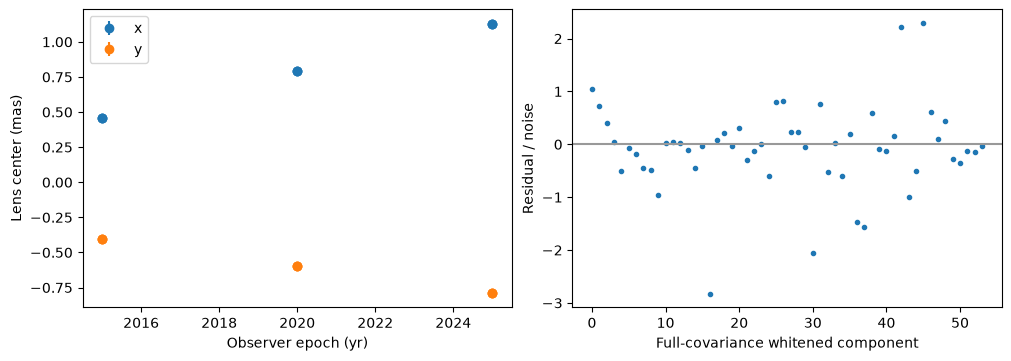

In [3]:
epochs = np.asarray(result['epochs_yr'])
track = np.asarray(result['center_track_mas'])
errors = np.asarray(result['center_track_sigma_mas'])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
for j, label in enumerate(['x', 'y']):
    axes[0].errorbar(epochs, track[:,j], yerr=errors[:,j], fmt='o', label=label)
axes[0].set(xlabel='Observer epoch (yr)', ylabel='Lens center (mas)')
axes[0].legend()
axes[1].plot(result['whitened_residuals'], 'o', ms=3)
axes[1].axhline(0, color='.6')
axes[1].set(xlabel='Full-covariance whitened component', ylabel='Residual / noise')
plt.show()

## Reoptimized likelihood
Local Gaussian errors are qualified by rank and active bounds. This curve refits the other parameters at each mass; its reference levels are not a universal boundary-coverage theorem.

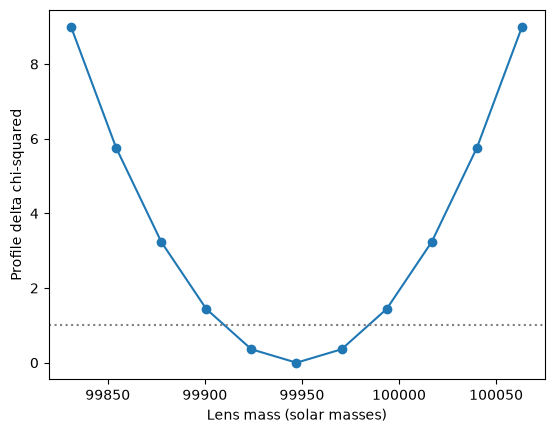

In [4]:
curve = profile(dataset, result, parameter='mass_msun', points=11)
plt.plot([p['value'] for p in curve['points']], [p['delta_chi2'] for p in curve['points']], '-o')
plt.axhline(1, color='.5', ls=':')
plt.xlabel('Lens mass (solar masses)'); plt.ylabel('Profile delta chi-squared'); plt.show()

## A required negative control
The same workflow must not declare a well-measured motion merely because a mass can be measured.

In [5]:
short_data, _ = make_example('cosmological_short_track')
short_result = fit(short_data, starts=2)
assert short_result['status'] != 'TRACKED'
{key: short_result[key] for key in ['status', 'motion_snr', 'uncertainty', 'diagnostics']}

{'status': 'PARTIALLY_IDENTIFIED',
 'motion_snr': 0.042407525385481516,
 'uncertainty': {'mass_msun': 1321952.91486703,
  'center_mas': [0.076331424138399, 0.0555356205465927],
  'proper_motion_mas_yr': [0.012136223932534856, 0.01244851544841484],
  'method': 'local Gaussian, known supplied covariance; no chi2 rescaling; null directions return null',
  'mass_68pct_interval_msun': [np.float64(996574236.0121795),
   np.float64(999218142.6152291)]},
 'diagnostics': [{'level': 'info',
   'code': 'COMPACT_EXTERIOR_ONLY',
   'message': 'The fit tracks a compact-lens exterior. It does not establish a black-hole horizon.'},
  {'level': 'info',
   'code': 'SYNTHETIC_DATA',
   'message': 'Recovery uses declared synthetic measurements, not an empirical detection.'},
  {'level': 'warning',
   'code': 'MOTION_UNRESOLVED',
   'message': 'Motion does not satisfy the declared five-sigma two-component tracking criterion.'},
  {'level': 'warning',
   'code': 'BOUND_ACTIVE',
   'message': 'A lens paramet

In [6]:
export_result(result, 'user_runs/notebook_baseline')
replay_check = replay_analysis('user_runs/notebook_baseline', 'user_runs/notebook_replayed')
assert replay_check['passed']
print('Exported original input, configuration, result, HTML, predictions, plots and hashes; replay passed.')

Exported original input, configuration, result, HTML, predictions, plots and hashes; replay passed.


The fixed 64-draw calibration and independent physical-unit/covariance tests are replayed by `python scripts/validate_product.py`. This notebook demonstrates inference and the BHSM interpretation of the same response; it does not replace the calibration protocol or uniquely identify a microscopic theory.